# ICCD753 Recuperación de Información

**Nombre:** Francisco Morales

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Instalación de dependencias
Se instalan las librerías : `nltk`, `pandas`/`pyarrow`, `huggingface_hub`, `flask`y `requests`.

In [1]:
%pip install -q nltk pandas pyarrow huggingface_hub flask requests matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 4. Descarga del corpus, consultas y qrels
Descargan de Hugging Face: corpus, queries y qrels de `BeIR/scifact` y`BeIR/scifact-qrels`.

In [2]:
from huggingface_hub import hf_hub_download
import os
os.makedirs("data", exist_ok=True)

def traer(repo, archivo, destino):
    if not os.path.exists(destino):
        import shutil
        shutil.copy(hf_hub_download(repo, archivo, repo_type="dataset"), destino)
    return destino

RUTA_CORPUS  = traer("BeIR/scifact",       "corpus/corpus-00000-of-00001.parquet",   "data/corpus.parquet")
RUTA_QUERIES = traer("BeIR/scifact",       "queries/queries-00000-of-00001.parquet", "data/queries.parquet")
RUTA_QRELS   = traer("BeIR/scifact-qrels", "test.tsv",                               "data/qrels_test.tsv")
print("Archivos listos:", RUTA_CORPUS, RUTA_QUERIES, RUTA_QRELS)

Archivos listos: data/corpus.parquet data/queries.parquet data/qrels_test.tsv


c:\Users\franc\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 5. Carga de datos en memoria
Carga de los archivos descargados.
- **Corpus:** `{doc_id: {title, text}}`. Se aplicando `html.unescape`, descartando documentos vacíos y sin fragmentación.
- **Consultas:** `{query_id: texto}`.
- **Qrels:** `{query_id: {doc_id: grado}}`, conservando solo grados > 0.

In [3]:
import re, math, html, json, heapq, time
from collections import Counter, defaultdict
from functools import lru_cache
import numpy as np, pandas as pd

def limpiar(t):
    return html.unescape(t or "").replace('""', '"').strip()

def cargar_corpus(ruta):
    df = pd.read_parquet(ruta)
    docs = {}
    for i, t, x in zip(df["_id"], df["title"], df["text"]):
        d = {"title": limpiar(t), "text": limpiar(x)}
        if d["title"] or d["text"]:
            docs[str(i)] = d
    return docs

def cargar_queries(ruta):
    df = pd.read_parquet(ruta)
    return {str(i): t for i, t in zip(df["_id"], df["text"])}

def cargar_qrels(ruta):
    qrels = defaultdict(dict)
    with open(ruta, encoding="utf-8") as f:
        next(f)
        for linea in f:
            qid, did, score = linea.rstrip("\n").split("\t")
            if int(score) > 0:
                qrels[qid][did] = int(score)
    return dict(qrels)

docs    = cargar_corpus(RUTA_CORPUS)
queries = cargar_queries(RUTA_QUERIES)
qrels   = cargar_qrels(RUTA_QRELS)
qrels = {q: {d: g for d, g in rel.items() if d in docs} for q, rel in qrels.items() if q in queries}
qrels = {q: rel for q, rel in qrels.items() if rel}
queries = {q: queries[q] for q in qrels}

print(f"Documentos: {len(docs)}")
print(f"Consultas de test con qrels: {len(qrels)}")
print(f"Pares (consulta, documento relevante): {sum(len(r) for r in qrels.values())}")
did = next(iter(docs)); qid0 = next(iter(queries))
print("\nEjemplo de documento:", did, "|", docs[did]["title"], "|", docs[did]["text"][:150], "...")
print("Ejemplo de consulta  :", qid0, "|", queries[qid0], "| relevantes:", qrels[qid0])

Documentos: 5183
Consultas de test con qrels: 300
Pares (consulta, documento relevante): 339

Ejemplo de documento: 4983 | Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging. | Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabi ...
Ejemplo de consulta  : 1 | 0-dimensional biomaterials show inductive properties. | relevantes: {'31715818': 1}


## 6. Preprocesamiento

| Paso | Decisión | Justificación |
|---|---|---|
| Texto indexado | Título y texto del documento concatenados, completos y sin fragmentar | DEbido a que el título trae términos clave del tema. La unidad de evaluación es el documento original, así que no se divide. |
| Tokenización | Minúsculas y expresión regular `[a-z0-9]+(?:-[a-z0-9]+)*` | Separa por cualquier signo de puntuación pero mantiene como una sola unidad los términos con guion debido a que en el documento hay presencia de nombres de genes, proteínas y células. |
| Normalización | Todo a minúsculas, `html.unescape` al cargar y descarte de tokens de un solo carácter | Evita distincion por mayusculas, limpia las entidades HTML. |
| Stopwords | Lista de inglés de NLTK | Debido a que el corpus esta en inglés. Palabras como `the`, `of` o `in` aparecen en casi todos los documentos y no ayudan a distinguirlos. |
| Stemming | Porter (NLTK) | Elegido para cubrir variantes de palabras y por ser rápido ademas de no depender de etiquetado gramatical. |

Aplicado a documentos y consultas.

In [4]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

STOP = set(stopwords.words("english"))
STEM = PorterStemmer()

@lru_cache(maxsize=None)
def raiz(token):
    return STEM.stem(token)

def preprocesar(texto):
    tokens = re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", texto.lower())
    return [raiz(t) for t in tokens if t not in STOP and len(t) > 1]

ejemplo = "Inhibition of IL-6 signalling reduces the risk of cardiovascular diseases in 2 trials."
print("Original :", ejemplo)
print("Procesado:", preprocesar(ejemplo))

Original : Inhibition of IL-6 signalling reduces the risk of cardiovascular diseases in 2 trials.
Procesado: ['inhibit', 'il-6', 'signal', 'reduc', 'risk', 'cardiovascular', 'diseas', 'trial']


## 7. Vocabulario e índice invertido
Construccion del índice invertido. Para cada documento se tokeniza título y texto, cuento cuántas veces aparece cada término y guardo esa frecuencia en indice[término][doc_id]. 

Adicionalemete se guarda la longitud de cada documento en tokens y la longitud promedio `avgdl` (para BM25) y la norma del vector TF-IDF de cada documento (para la similitud coseno). Cada entrada del índice usa el `doc_id` original, de modo que se conserva la relación con el corpus y los qrels.

In [5]:
def idf(t, idx):
    return math.log(1 + idx["N"] / len(idx["indice"][t]))

def peso_tf(f):
    return 1 + math.log(f)

def construir_indice(docs):
    indice, longitud = defaultdict(dict), {}
    for doc_id, d in docs.items():
        tokens = preprocesar(f"{d['title']} {d['text']}")
        longitud[doc_id] = len(tokens)
        for t, f in Counter(tokens).items():
            indice[t][doc_id] = f
    idx = {"indice": dict(indice), "len": longitud, "N": len(docs),
           "avgdl": sum(longitud.values()) / len(docs)}
    normas = defaultdict(float)
    for t, postings in idx["indice"].items():
        w = idf(t, idx)
        for d, f in postings.items():
            normas[d] += (peso_tf(f) * w) ** 2
    idx["normas"] = {d: math.sqrt(v) for d, v in normas.items()}
    return idx

t0 = time.perf_counter()
idx = construir_indice(docs)
print(f"Índice construido en {time.perf_counter()-t0:.1f} s")
print(f"Documentos indexados (N): {idx['N']}  |  Vocabulario: {len(idx['indice'])} términos  |  avgdl: {idx['avgdl']:.1f}")
print("Términos con mayor df:", [(t, len(p)) for t, p in sorted(idx["indice"].items(), key=lambda x: -len(x[1]))[:10]])

Índice construido en 1.5 s
Documentos indexados (N): 5183  |  Vocabulario: 37322 términos  |  avgdl: 139.6
Términos con mayor df: [('cell', 2453), ('result', 2372), ('studi', 2211), ('use', 2181), ('activ', 1780), ('show', 1578), ('increas', 1528), ('express', 1502), ('function', 1487), ('also', 1474)]


## 8. Modelos de recuperación

Implementacion con los dos modelos:

- **TF-IDF con similitud coseno:** Realiza el producto punto con cada documento y el resultado se divide entre la norma de la consulta y la del documento. Comparando asi la dirección de los vectores.
- **BM25:** uso idf = log((N − df + 0.5)/(df + 0.5) + 1) y la fórmula con saturación de frecuencia y normalización por longitud, con los valores k1 = 1.5 y b = 0.75.

La función buscar(modelo, consulta, k) junta ambos: ordena de mayor a menor puntaje, desempata por identificador para que el resultado sea siempre el mismo y devuelve los k primeros.

In [6]:
def tfidf(consulta, idx):
    q = Counter(preprocesar(consulta))
    scores, norma_q = defaultdict(float), 0.0
    for t, fq in q.items():
        if t not in idx["indice"]:
            continue
        w = idf(t, idx)
        wq = peso_tf(fq) * w
        norma_q += wq ** 2
        for d, f in idx["indice"][t].items():
            scores[d] += wq * peso_tf(f) * w
    norma_q = math.sqrt(norma_q)
    return {d: s / (norma_q * idx["normas"][d]) for d, s in scores.items()}

def bm25(consulta, idx, k1=1.5, b=0.75):
    scores = defaultdict(float)
    for t in set(preprocesar(consulta)):
        if t not in idx["indice"]:
            continue
        df = len(idx["indice"][t])
        w = math.log((idx["N"] - df + 0.5) / (df + 0.5) + 1)
        for d, f in idx["indice"][t].items():
            scores[d] += w * f * (k1 + 1) / (f + k1 * (1 - b + b * idx["len"][d] / idx["avgdl"]))
    return dict(scores)

MODELOS = {"tfidf": tfidf, "bm25": bm25}

def buscar(modelo, consulta, k=10):
    scores = MODELOS[modelo](consulta, idx)
    return heapq.nsmallest(k, scores.items(), key=lambda x: (-x[1], x[0]))

q = queries[qid0]
print("Consulta:", q, "\n")
for m in MODELOS:
    print(f"--- {m} ---")
    for r, (d, s) in enumerate(buscar(m, q, 5), 1):
        print(f"{r}. {d:>10s}  score={s:.4f}  {'[RELEVANTE]' if d in qrels[qid0] else '':12s} {docs[d]['title'][:65]}")

Consulta: 0-dimensional biomaterials show inductive properties. 

--- tfidf ---
1.   13231899  score=0.1445               In situ regulation of DC subsets and T cells mediates tumor regre
2.   21257564  score=0.0775               How long will long-term potentiation last?
3.   18953920  score=0.0701               The Epithelial-Mesenchymal Transition Generates Cells with Proper
4.    7581911  score=0.0620               Human embryonic stem cells with biological and epigenetic charact
5.   35008773  score=0.0548               Neural induction and early patterning in vertebrates.
--- bm25 ---
1.   18953920  score=10.3489               The Epithelial-Mesenchymal Transition Generates Cells with Proper
2.   21257564  score=9.4247               How long will long-term potentiation last?
3.   10906636  score=8.2347               The carboxyl terminus of human cytomegalovirus-encoded 7 transmem
4.    7581911  score=8.0771               Human embryonic stem cells with biological and epigenetic 

## 9. Métricas de evaluación

Creacion de metricas para el ranking y los documentos relevantes de una consulta:

- **Precision@k:** calculo de precision de los k primeros resultados.
- **Recall@k:** calculo del recall de todos los documentos relevantes.
- **NDCG@k:** Uso ganancia 2^g − 1 y descuento log2(i+1), y divido entre el DCG ideal.
- **AP** para MAP@100 promedio de la precisión en cada posición donde aparece un relevante.

La función evaluar aplica todo esto a cada consulta de test. Recupera los 100 primeros de cada una (hace falta esa profundidad para MAP@100) y devuelve una tabla con una fila por consulta. Antes de usarlas hago una comprobación sencilla: un ranking perfecto debe dar NDCG igual a 1, y así fue.

In [7]:
def precision_recall(ranking, rel, k):
    aciertos = sum(1 for d in ranking[:k] if d in rel)
    return aciertos / k, aciertos / len(rel)

def dcg(grados):
    return sum((2 ** g - 1) / math.log2(i + 1) for i, g in enumerate(grados, 1))

def ndcg(ranking, rel, k):
    idcg = dcg(sorted(rel.values(), reverse=True)[:k])
    return dcg([rel.get(d, 0) for d in ranking[:k]]) / idcg if idcg else 0.0

def average_precision(ranking, rel):
    aciertos, suma = 0, 0.0
    for i, d in enumerate(ranking, 1):
        if d in rel:
            aciertos += 1
            suma += aciertos / i
    return suma / len(rel)

def evaluar(modelo, k=10, profundidad=100):
    filas = []
    for qid, rel in qrels.items():
        ranking = [d for d, _ in buscar(modelo, queries[qid], profundidad)]
        p, r = precision_recall(ranking, rel, k)
        filas.append({"qid": qid, "consulta": queries[qid], "n_rel": len(rel),
                      f"P@{k}": p, f"R@{k}": r, f"NDCG@{k}": ndcg(ranking, rel, k),
                      "AP": average_precision(ranking, rel)})
    return pd.DataFrame(filas)

## 10. Evaluación sobre la partición test

**Consultas utilizadas:** las 300 consultas de test que tienen qrels. La celda imprime cuántas son y los primeros diez ids; la lista completa corresponde a las consultas de qrels_test.tsv que pasaron el filtro del paso 5.

Se calculan Precision@10, Recall@10, NDCG@10 y MAP@100 para cada consulta con ambos modelos y luego se promedian.

In [8]:
K = 10
print(f"Consultas evaluadas: {len(qrels)}  |  primeros ids: {list(qrels)[:10]}")
res = {m: evaluar(m, K) for m in MODELOS}
resumen = pd.DataFrame({m: df[[f"P@{K}", f"R@{K}", f"NDCG@{K}", "AP"]].mean() for m, df in res.items()}).T
resumen = resumen.rename(columns={"AP": "MAP@100"})
resumen.round(4)

Consultas evaluadas: 300  |  primeros ids: ['1', '3', '5', '13', '36', '42', '48', '49', '50', '51']


,P@10,R@10,NDCG@10,MAP@100
tfidf,0.0887,0.8110,0.6335,0.5771
bm25,0.0883,0.8022,0.6692,0.6285


## 11. Comparación de TF-IDF y BM25
Se compara el NDCG@10 **consulta por consulta**: en cuántas gana cada modelo (umbral de 0.02 para considerar empate), la diferencia media y su **intervalo de confianza bootstrap al 95 %** para saber si la diferencia es distinguible de cero.

In [9]:
M = f"NDCG@{K}"
dif = res["bm25"][M].values - res["tfidf"][M].values
UMBRAL = 0.02
gana_bm25, gana_tfidf = int((dif > UMBRAL).sum()), int((dif < -UMBRAL).sum())
rng = np.random.default_rng(0)
ic = np.percentile(rng.choice(dif, size=(2000, len(dif)), replace=True).mean(axis=1), [2.5, 97.5])

print(f"BM25 mejor en {gana_bm25} consultas | TF-IDF mejor en {gana_tfidf} | similares en {len(dif)-gana_bm25-gana_tfidf}")
print(f"Diferencia media de {M} (BM25 − TF-IDF): {dif.mean():+.4f}   IC95% bootstrap: [{ic[0]:+.4f}, {ic[1]:+.4f}]")
print("¿Diferencia distinguible de 0?:", "SÍ" if ic[0] > 0 or ic[1] < 0 else "NO")

BM25 mejor en 69 consultas | TF-IDF mejor en 37 | similares en 194
Diferencia media de NDCG@10 (BM25 − TF-IDF): +0.0357   IC95% bootstrap: [+0.0144, +0.0575]
¿Diferencia distinguible de 0?: SÍ


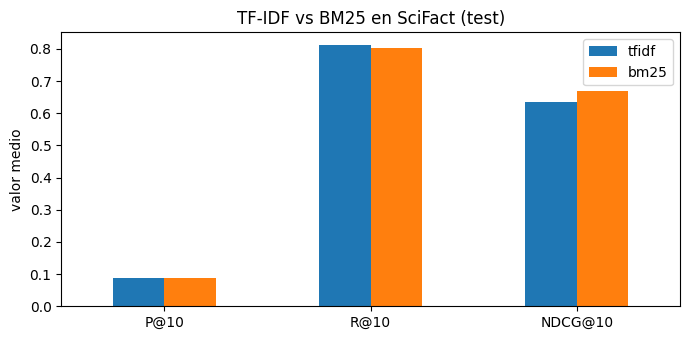

Consultas donde BM25 supera más a TF-IDF:


,qid,consulta,n_rel,NDCG_bm25,NDCG_tfidf,dif
15,72,Activator-inhibitor pairs are provided dorsally by Admpchordin.,1,1.0,0.386853,0.613147
139,644,Insulin increases risk of severe kidney failure.,1,1.0,0.386853,0.613147
219,1024,Recurrent mutations occur frequently within CTCF anchor sites adja...,1,1.0,0.430677,0.569323
123,569,"In adult tissue, most T cells are memory T cells.",1,1.0,0.430677,0.569323
11,54,AMP-activated protein kinase (AMPK) activation increases inflammat...,1,1.0,0.500000,0.500000


Consultas donde TF-IDF supera más a BM25:


,qid,consulta,n_rel,NDCG_bm25,NDCG_tfidf,dif
177,820,N-terminal cleavage increases success identifying transcription st...,1,0.000000,0.63093,-0.630930
178,821,N-terminal cleavage reduces success identifying transcription star...,1,0.000000,0.63093,-0.630930
29,133,Assembly of invadopodia is triggered by focal generation of phosph...,5,0.102097,0.60604,-0.503942
145,690,Less than 10% of the gabonese children with Schimmelpenning-Feuers...,1,0.500000,1.00000,-0.500000
83,388,Ethanol stress decreases the expression of IBP in bacteria.,1,0.500000,1.00000,-0.500000


In [10]:
import matplotlib.pyplot as plt
resumen[[f"P@{K}", f"R@{K}", f"NDCG@{K}"]].T.plot.bar(rot=0, figsize=(7, 3.5), title="TF-IDF vs BM25 en SciFact (test)")
plt.ylabel("valor medio"); plt.tight_layout(); plt.show()

t = res["bm25"][["qid", "consulta", "n_rel", M]].rename(columns={M: "NDCG_bm25"})
t["NDCG_tfidf"] = res["tfidf"][M].values
t["dif"] = t["NDCG_bm25"] - t["NDCG_tfidf"]
pd.set_option("display.max_colwidth", 70)
print("Consultas donde BM25 supera más a TF-IDF:");  display(t.sort_values("dif", ascending=False).head(5))
print("Consultas donde TF-IDF supera más a BM25:");  display(t.sort_values("dif").head(5))

## 12. Interpretación de resultados

In [11]:
mejor, peor = resumen[M].idxmax(), resumen[M].idxmin()
rel_media = np.mean([len(r) for r in qrels.values()])
print(f"• Con {M}, el mejor modelo es {mejor.upper()} ({resumen.loc[mejor, M]:.3f}) frente a {peor.upper()} ({resumen.loc[peor, M]:.3f}).")
print(f"• Precision@{K} es baja en ambos modelos porque cada consulta tiene pocos documentos relevantes (media {rel_media:.1f}); "
      f"la precisión máxima alcanzable en el top-{K} es ≈ {np.mean([min(len(r), K)/K for r in qrels.values()]):.2f}.")
print(f"• Recall@{K} = {resumen.loc[mejor, f'R@{K}']:.3f} en {mejor.upper()}: esa fracción de los relevantes aparece en el top-{K}.")
print(f"• BM25 gana en {gana_bm25} consultas y TF-IDF en {gana_tfidf}; diferencia media {dif.mean():+.4f} (IC95% [{ic[0]:+.4f}, {ic[1]:+.4f}]).")

• Con NDCG@10, el mejor modelo es BM25 (0.669) frente a TFIDF (0.633).
• Precision@10 es baja en ambos modelos porque cada consulta tiene pocos documentos relevantes (media 1.1); la precisión máxima alcanzable en el top-10 es ≈ 0.11.
• Recall@10 = 0.802 en BM25: esa fracción de los relevantes aparece en el top-10.
• BM25 gana en 69 consultas y TF-IDF en 37; diferencia media +0.0357 (IC95% [+0.0144, +0.0575]).


### Interpretación

| Métrica | TF-IDF | BM25 |
|---|---|---|
| Precision@10 | 0.0887 | 0.0883 |
| Recall@10 | 0.8110 | 0.8022 |
| NDCG@10 | 0.6335 | 0.6692 |
| MAP@100 | 0.5771 | 0.6285 |

En las métricas que miden la calidad del orden BM25 sale por delante: NDCG@10 sube de 0.634 a 0.669 y MAP@100 de 0.577 a 0.629. En Precision@10 y Recall@10 ambos modelos están  cercanos uno del otro. Por lo que los dos encuentran casi los mismos documentos relevantes dentro de los diez primeros, pero BM25 los coloca en posiciones más altas. Por ejemplo, en las consultas 72, 644, 1024 y 569 BM25 pone el documento relevante en primer lugar y TF-IDF lo deja alrededor de la posición 4 o 5.

Cada consulta tiene en promedio solo 1.1 documentos relevantes. Los modelos llegan a 0.088, cerca del 78 % de ese techo. Para este corpus las métricas más informativas son Recall y NDCG.

Con un Recall@10 de entre 0.80 y 0.81, en promedio cerca del 80 % de los documentos relevantes aparece entre los diez primeros. El 20 % restante queda fuera del top-10, debido a que comparte poco vocabulario con la consulta.

BM25 gana en 69 consultas y TF-IDF en 37, y en 194 (casi dos tercios) el resultado es prácticamente igual. La diferencia media de NDCG@10 es de +0.036 y su intervalo de confianza del 95 % ([+0.014, +0.058]) no incluye el cero, así que con estas 300 consultas la ventaja de BM25 es estadísticamente distinguible de cero. Aun así es una mejora moderada, de unos 3 o 4 puntos de NDCG, y no una diferencia enorme.